# Satellite validation and calibration of the offshore hindcast

Compares the offshore hindcast at the goals (`offshore_waves`, e.g. WHACS) with
satellite altimetry, and calibrates it per goal:

1. **Passes at each goal** — altimeter observations within `radius_km` of each
   goal's hindcast node, in water deeper than `min_depth`, with good quality
   flags; one median Hs per satellite pass; the hindcast at the pass time.
2. **Calibration per goal** — directional calibration (wind sea and swell, per
   direction sector; Mínguez et al., 2011) fitted on `train_fraction` of the
   passes (75 % by default) and validated on the rest.
3. **Calibrated hindcast** — written as a new zarr, to add to `offshore_waves`
   (e.g. `WHACS_cal`) and use in 08 onwards like any other offshore source.

Everything comes from the `satellite` block of the case JSON. Nothing here is
specific to one hindcast: any `offshore_waves` entry on `(time, goal)` with
`hs`, `dir` (and partitions `phs{i}`, `pdir{i}`) works.

**Prerequisites:** `07a_Download_Process_WHACS.ipynb` (the goal zarr) and the
altimeter store (`satellite.data_path`). Method and choices:
`hywaves/docs/satellite_calibration.md` in the main HyGloW repository.

In [1]:
import json
import os
import sys

# GDAL/PROJ data paths when the kernel was not started through `conda activate`
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import calibration as cal
from utils import viz

## Configuration

In [2]:
offshore_name = "WHACS"  # offshore_waves entry to validate and calibrate (e.g. "ERA5")

cfg = cal.config()
print(json.dumps(cfg, indent=1))

{
 "name": "IMOS altimeter",
 "radius_km": 25,
 "min_depth": 15,
 "flags": [
  1,
  2
 ],
 "max_time_diff": "30min",
 "max_gap": "5min",
 "min_points": 3,
 "train_fraction": 0.75,
 "split": "random",
 "seed": 0,
 "sector_size": 22.5,
 "min_samples": 20,
 "data_path": "https://geoocean.unican.es/zarr/IMOS/imos_altimeter_1985_2020.zarr"
}


## 1. Satellite passes at each goal

Cached in `outputs/calibration/{offshore_name}/pairs.csv`; `refresh=True`
recomputes them (e.g. after changing `radius_km` or `min_depth`).

In [3]:
pairs = cal.satellite_pairs(offshore_name, refresh=True)
pairs.groupby("goal").size().rename("passes").to_frame().T

goal,1,10,2,3,4,5,6,7,8,9
passes,1064,1021,1448,923,1263,3014,2329,1023,2132,2265


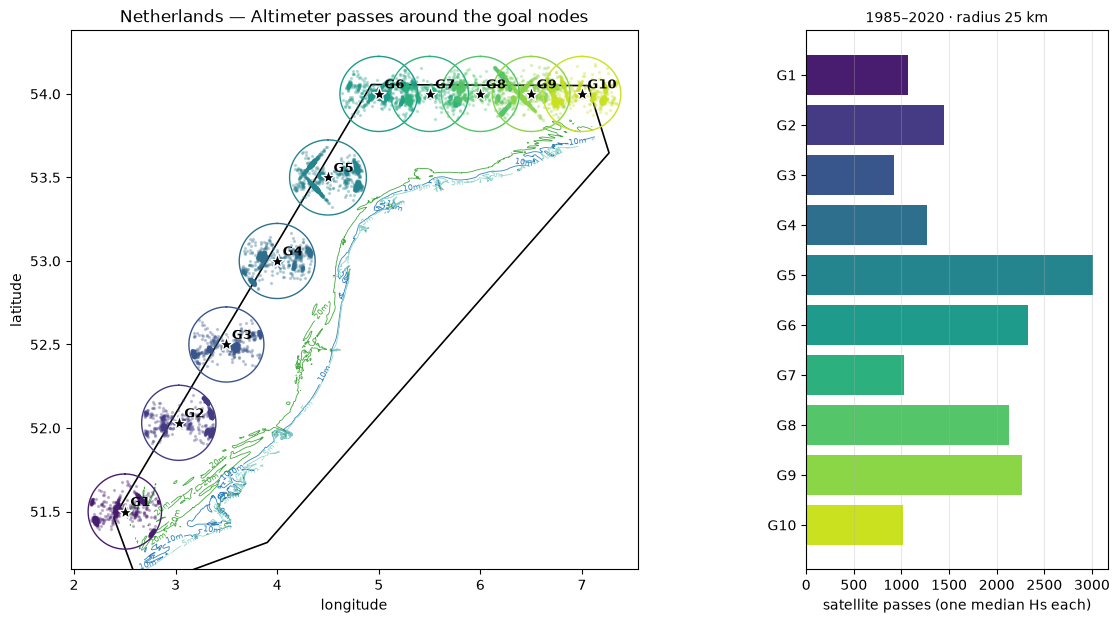

In [4]:
fig = viz.plot_satellite_pairs(pairs, cal.goal_nodes(offshore_name), cfg["radius_km"])

## 2. Calibration per goal

Fitted on `train_fraction` of each goal's passes; the metrics below are on the
**test** passes, which the fit never saw (bias = hindcast − satellite).

In [5]:
calibrations = cal.fit_calibration(offshore_name)
metrics = cal.calibration_metrics(offshore_name)
metrics[metrics["set"] == "test"].pivot(
    index="goal", columns="stage", values=["n", "bias", "rmse", "slope"]
).round(3)

n              bias              rmse             slope       
stage calibrated    raw calibrated    raw calibrated    raw calibrated    raw
goal                                                                         
1          266.0  266.0     -0.045 -0.096      0.258  0.273      0.939  0.886
10         255.0  255.0      0.074  0.001      0.276  0.268      1.000  0.902
2          361.0  361.0      0.010 -0.065      0.221  0.227      0.965  0.907
3          230.0  230.0      0.022 -0.068      0.232  0.236      0.935  0.867
4          315.0  315.0      0.083 -0.067      0.252  0.257      0.970  0.840
5          752.0  752.0      0.087 -0.088      0.282  0.291      0.952  0.826
6          580.0  580.0      0.060 -0.112      0.248  0.289      0.959  0.833
7          256.0  256.0      0.031 -0.062      0.308  0.313      0.931  0.850
8          532.0  532.0      0.043 -0.068      0.237  0.263      0.955  0.861
9          566.0  566.0      0.064 -0.040      0.246  0.237      1.018  0.898

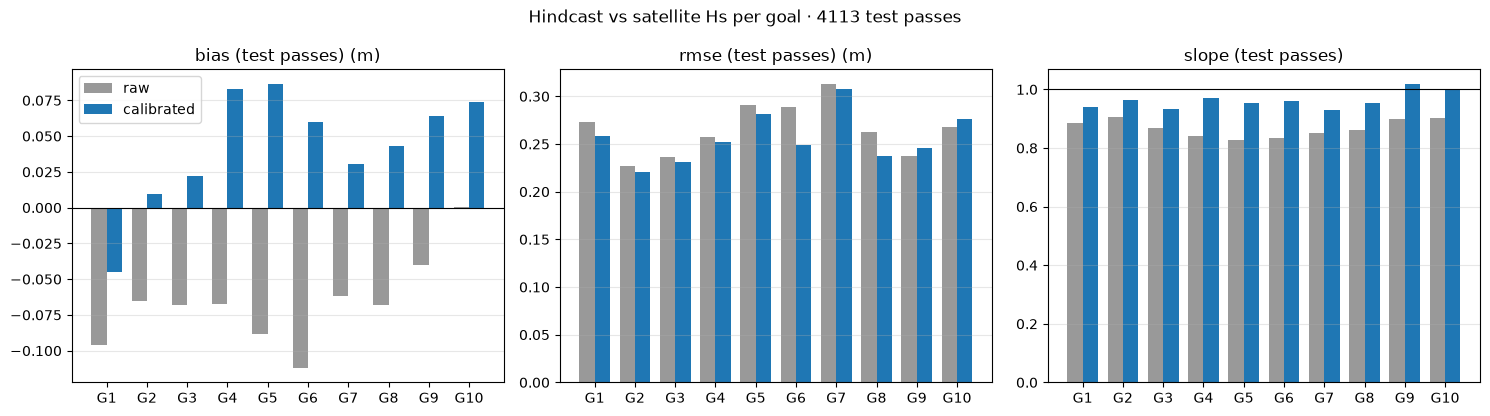

In [6]:
fig = viz.plot_calibration_metrics(metrics, subset="test")

Per goal: test passes before and after the calibration, and the Hs factor of
each direction sector for wind sea and swell (red above 1, blue below, grey =
not enough data, left at 1).

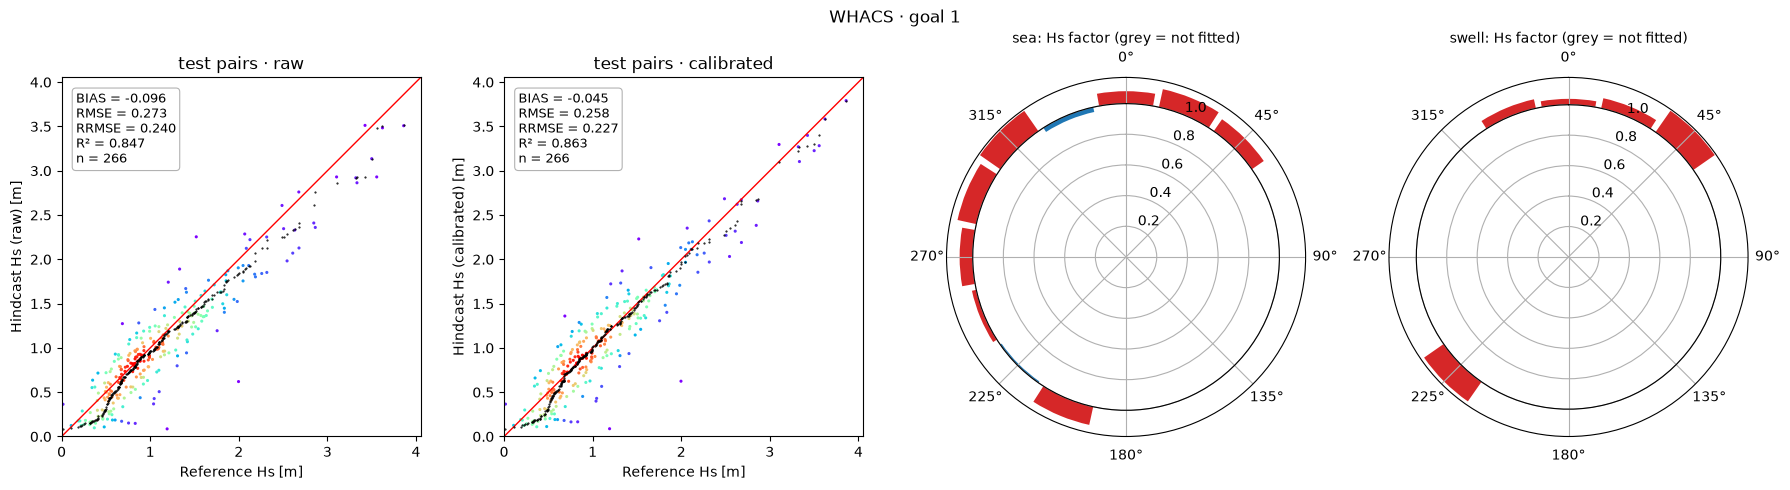

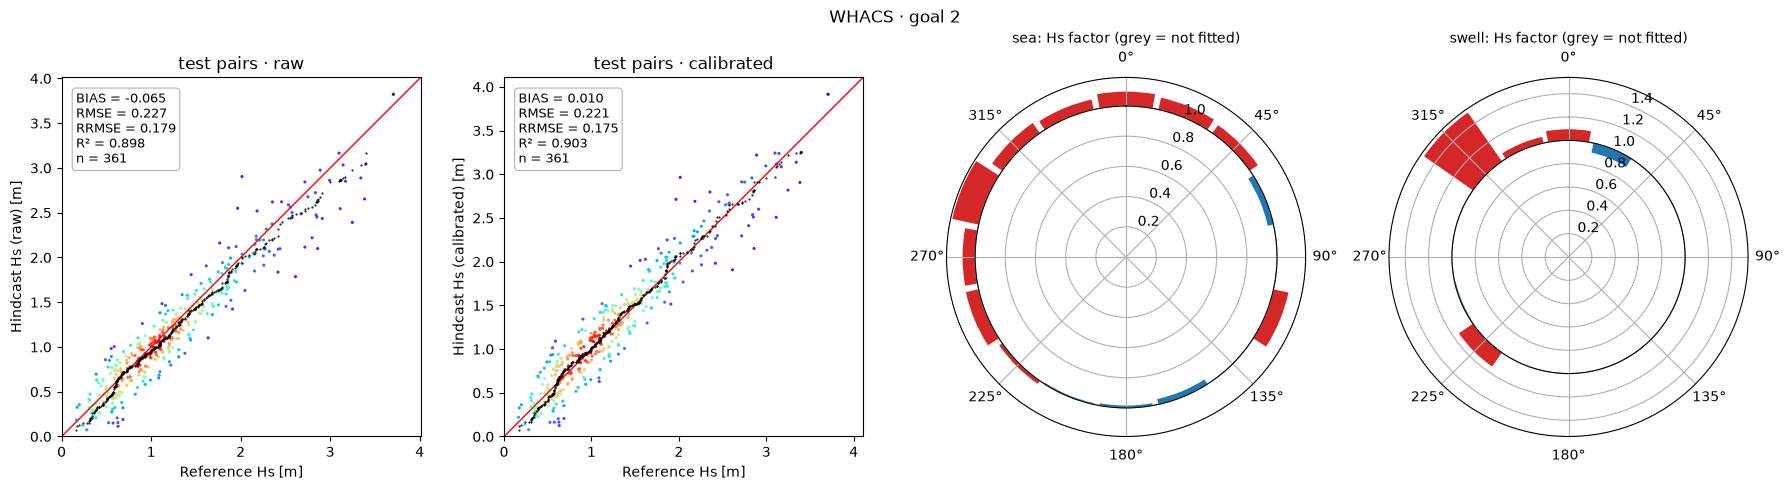

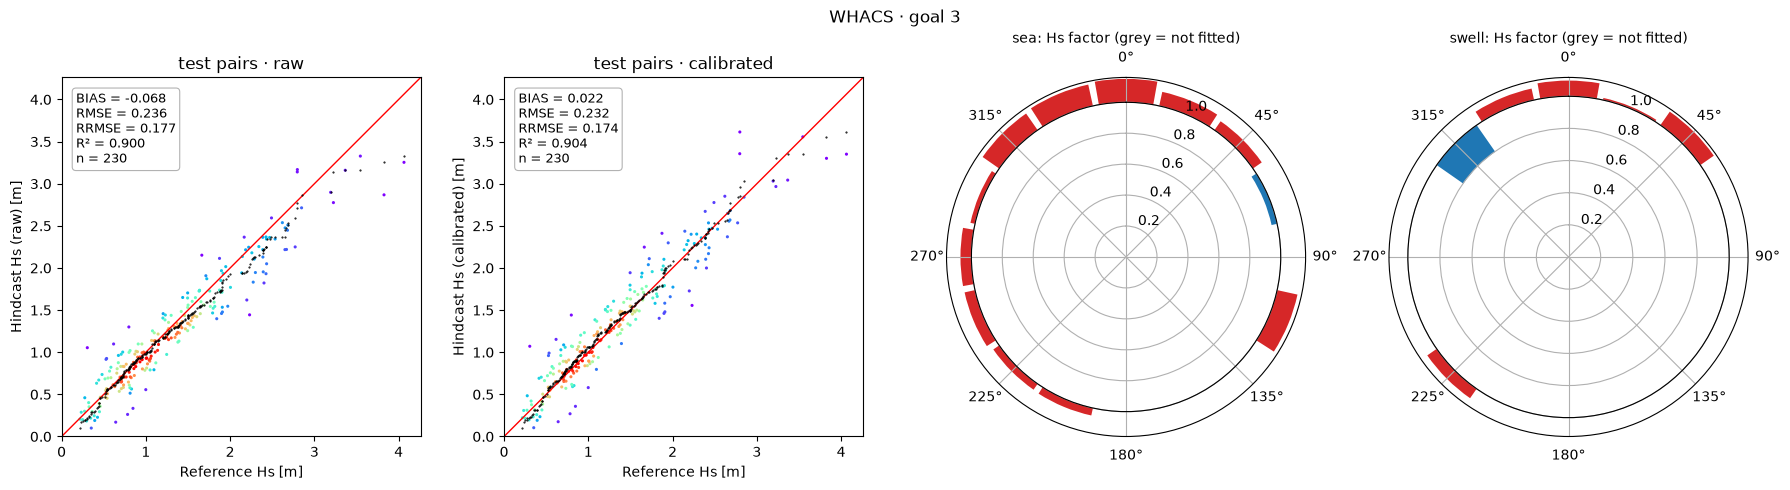

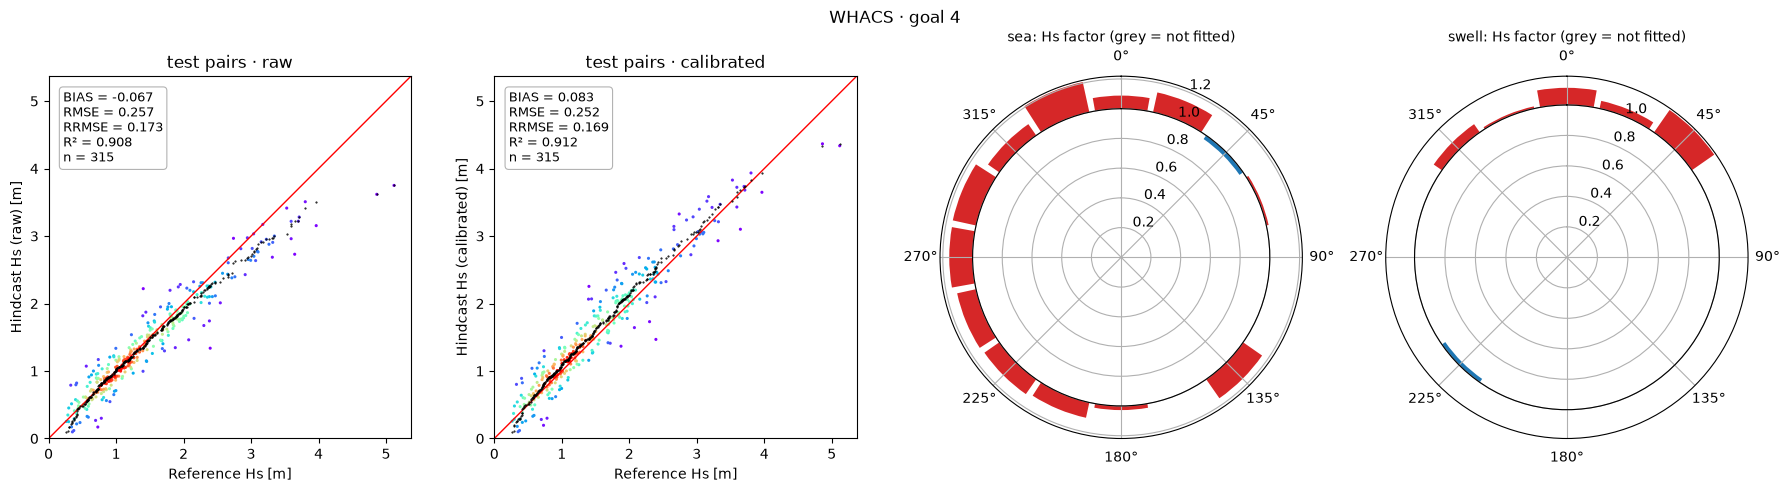

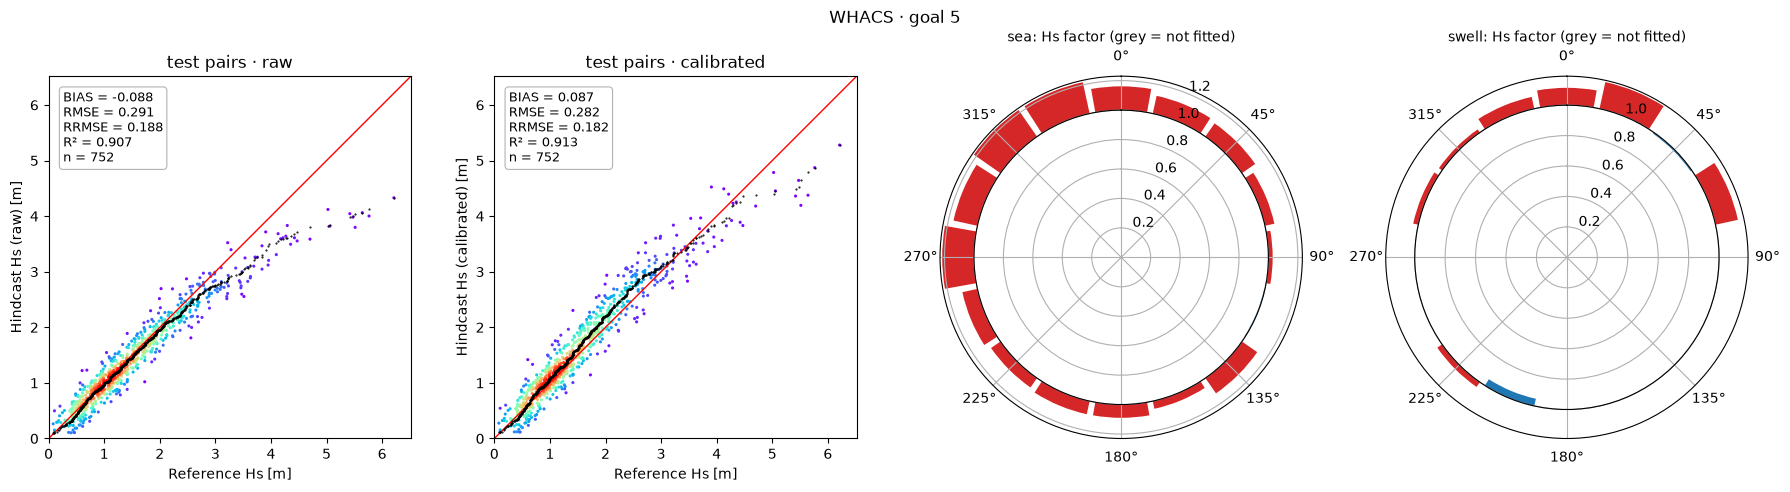

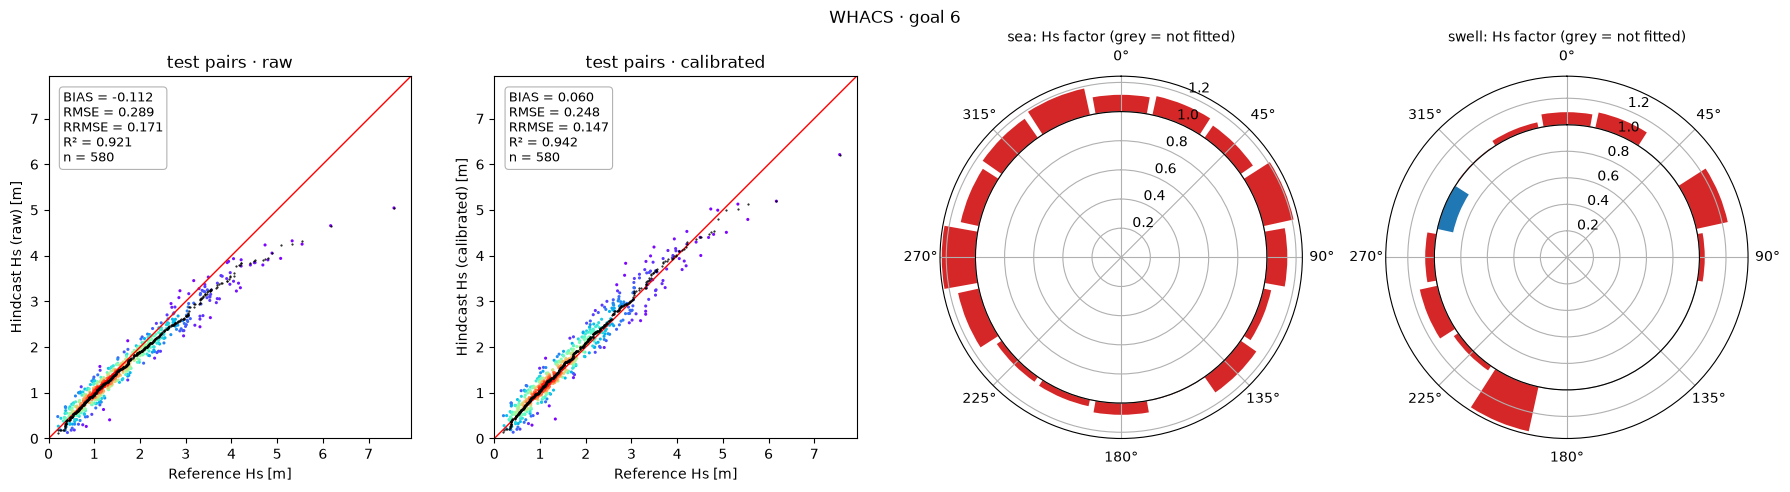

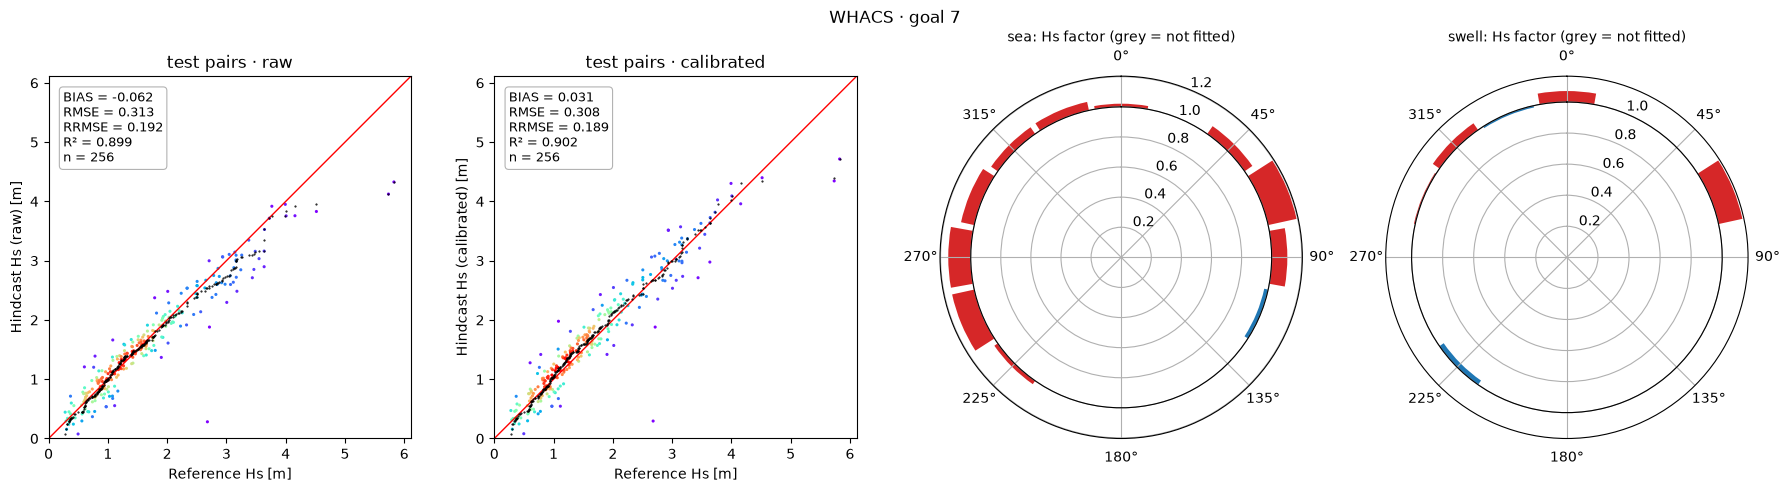

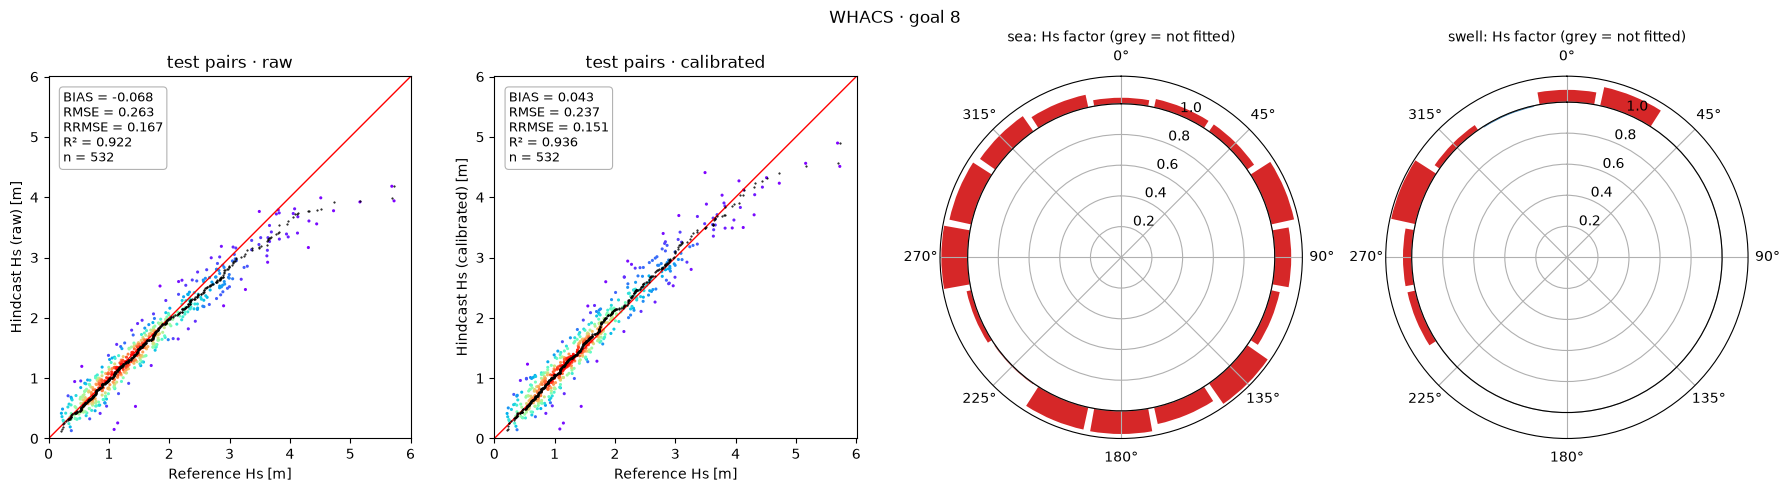

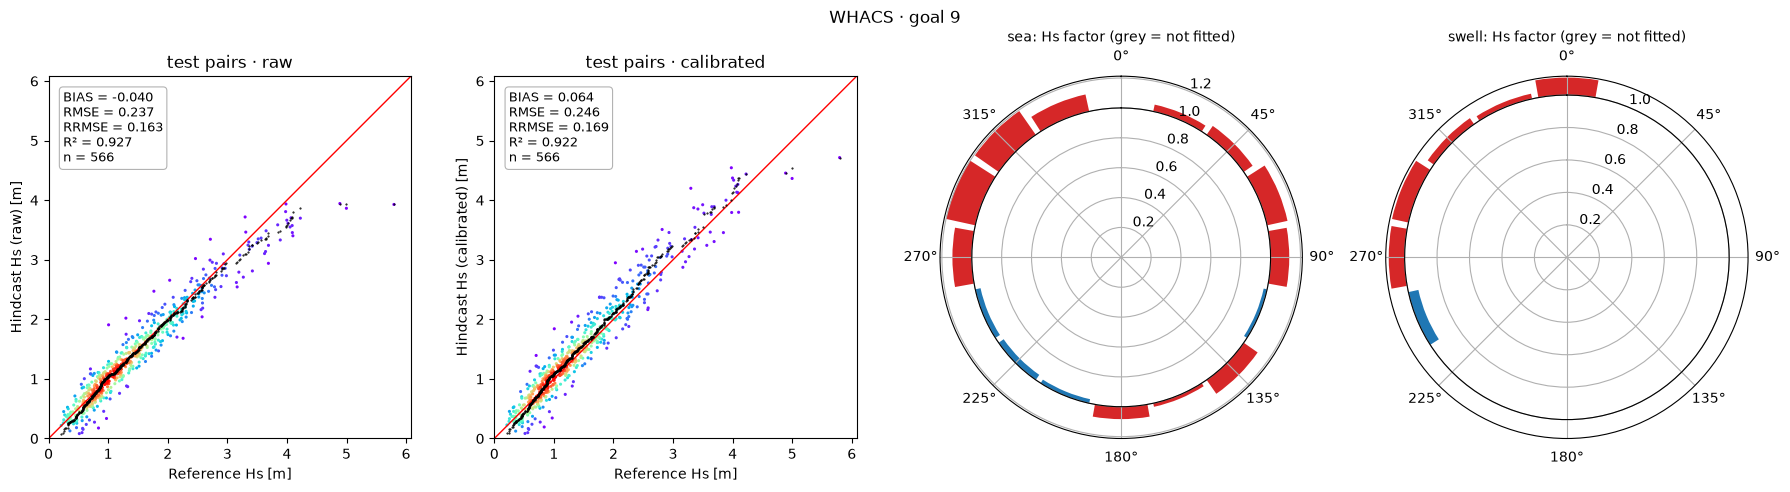

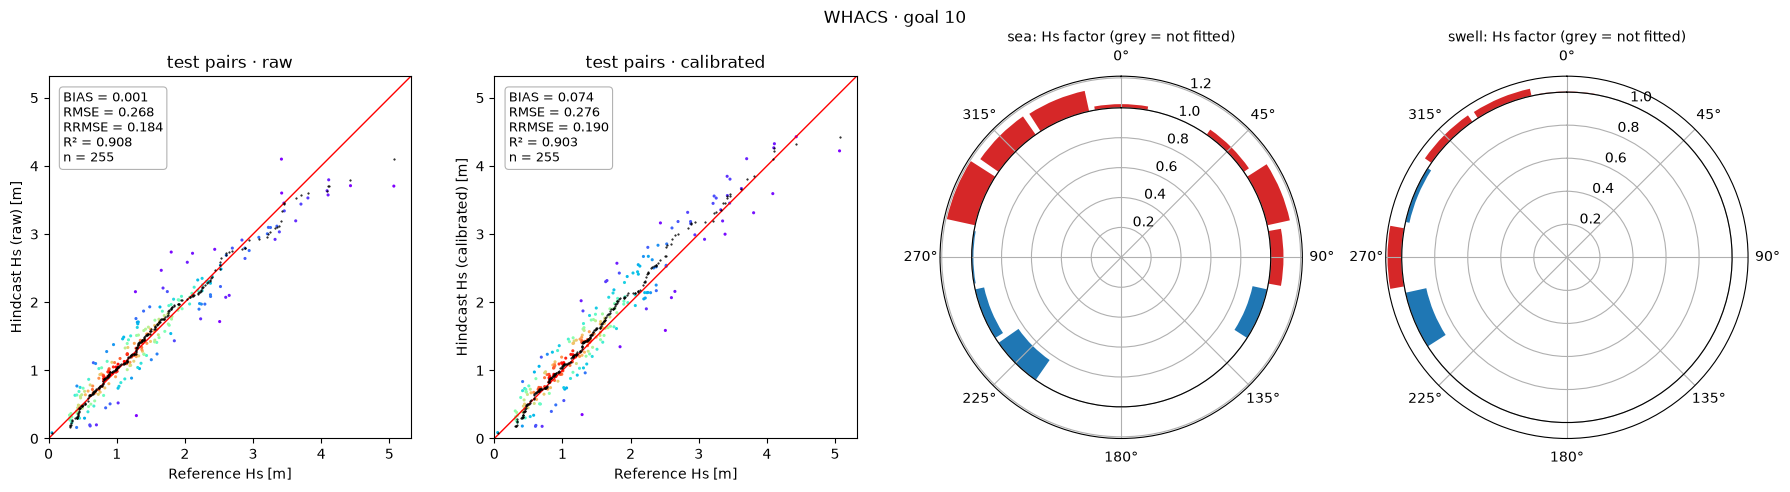

In [7]:
for gid, calval in calibrations.items():
    calval.plot(title=f"{offshore_name} · goal {gid}")

## 3. Write the calibrated hindcast

Applies each goal's factors to the whole record (partition Hs times its
sector factor, bulk Hs rescaled; periods and directions unchanged) and writes
`*_cal.zarr` next to the source. Add the printed entry to `offshore_waves` in
the case JSON.

In [8]:
entry = cal.write_calibrated_hindcast(offshore_name)
print(json.dumps(entry, indent=4))

{
    "name": "WHACS_cal",
    "data_path": "inputs/WHACS/processed/Netherlands_WHACS_goal_cal.zarr",
    "hindcast": "WHACS"
}


## Next

- Add the entry above to `offshore_waves` in the case JSON.
- `08_Dynamic_Cases_Generation.ipynb` with `offshore_name = "WHACS_cal"` (the
  dynamic runs must be forced with the calibrated hindcast too, so that 09
  compares like with like), then 09–12 with the same name.
- `10a_Validate_Offshore_Buoys.ipynb` with both names: the offshore buoys are an
  independent check of the calibration.